DEBUG: Загруженный TINKOFF_SANDBOX_TOKEN: 't.xEU...k9aaw'
INFO: Робот будет искать прогнозы для следующих ключевых частей имен моделей: ['Model_1min_TF_30d_hist_30m_', 'Model_5min_TF_60d_hist_10h_', 'Model_10min_TF_90d_hist_1day_']
--- Запуск торгового робота в песочнице Tinkoff ---

--- Загрузка файлов с прогнозами по типам моделей ---
  Для типа модели (ключ: 'Model_1min_TF_30d_hist_30m_'):
    Загружено и объединено 1 файла(ов): predictions_BBG004730N88_Model_1min_TF_30d_hist_30m_pred_NEWS_20250525_211953.csv
    Итого 30 уникальных строк прогнозов для типа 'Model_1min_TF_30d_hist_30m_'.
  Для типа модели (ключ: 'Model_5min_TF_60d_hist_10h_'):
    Загружено и объединено 1 файла(ов): predictions_BBG004730N88_Model_5min_TF_60d_hist_10h_pred_NEWS_20250525_210803.csv
    Итого 120 уникальных строк прогнозов для типа 'Model_5min_TF_60d_hist_10h_'.
  Для типа модели (ключ: 'Model_10min_TF_90d_hist_1day_'):
    Загружено и объединено 1 файла(ов): predictions_BBG004730N88_Model_10min_TF_90d

2a60ac6e30ac29d912ed976882fd7407 PostSandboxOrder INVALID_ARGUMENT 30079


Ошибка API Tinkoff при размещении ордера: (<StatusCode.INVALID_ARGUMENT: (3, 'invalid argument')>, '30079', Metadata(tracking_id='2a60ac6e30ac29d912ed976882fd7407', ratelimit_limit='200, 200;w=60', ratelimit_remaining=197, ratelimit_reset=1, message='Instrument is not available for trading'))
    Сделка не удалась: (<StatusCode.INVALID_ARGUMENT: (3, 'invalid argument')>, '30079', Metadata(tracking_id='2a60ac6e30ac29d912ed976882fd7407', ratelimit_limit='200, 200;w=60', ratelimit_remaining=197, ratelimit_reset=1, message='Instrument is not available for trading'))
  Текущая позиция: 0 акций, ср. цена входа: 0.0000
  Ожидание 10 мин...

--- Цикл 2 (2025-05-26 00:49:57 MSK) ---


8f25b986cbfe2e6acf6c01dfb429926e PostSandboxOrder INVALID_ARGUMENT 30079


  Текущая рыночная цена: 302.2200
  Цена не изменилась (302.2200). Время без изменений: 10.00 мин.
  Анализ прогнозов по типам моделей на следующие 10 минут.
  Окно поиска UTC: (2025-05-25 21:49:57, 2025-05-25 21:59:57]
  Окно поиска MSK: (2025-05-26 00:49:57 MSK, 2025-05-26 00:59:57 MSK]
    Тип 'Model_1min_TF_30d_hist_30m_': нет прогнозов в окне на следующие 10 минут.
    Тип 'Model_5min_TF_60d_hist_10h_': найден прогноз 300.4346 на 2025-05-26 00:55:00 MSK
    Тип 'Model_10min_TF_90d_hist_1day_': найден прогноз 304.3176 на 2025-05-26 00:50:00 MSK
  Итоговый средний прогноз на ~10 мин: 302.3761
  РЕШЕНИЕ: Купить 10 акций. Цель: 10, Сейчас: 0. Ожидается рост цены.
  Попытка ордера: FIGI=BBG004730N88, Лоты=1, Направление=ORDER_DIRECTION_BUY
Ошибка API Tinkoff при размещении ордера: (<StatusCode.INVALID_ARGUMENT: (3, 'invalid argument')>, '30079', Metadata(tracking_id='8f25b986cbfe2e6acf6c01dfb429926e', ratelimit_limit='200, 200;w=60', ratelimit_remaining=199, ratelimit_reset=51, message

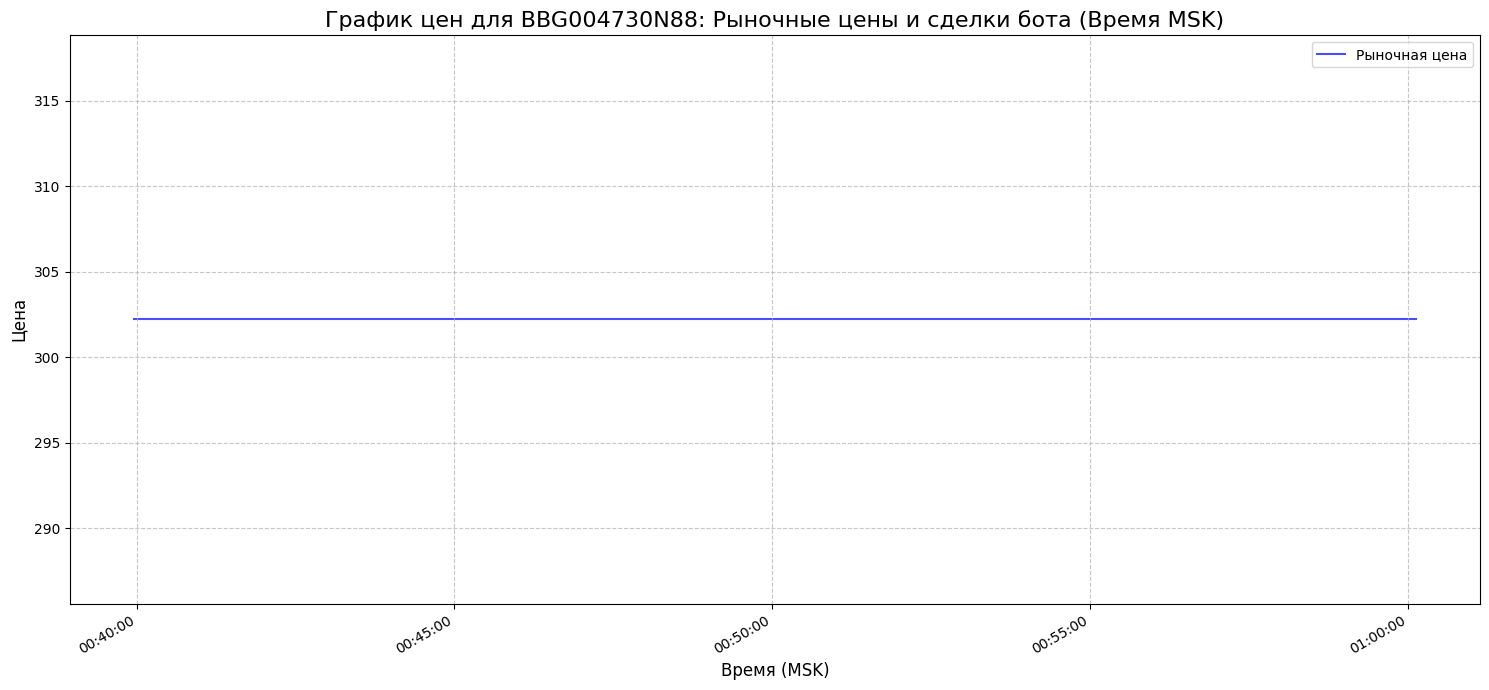

Недостаточно данных о доходности для графика.
Счет песочницы 08191220-141f-4e8b-a88b-f175b0928bd7 закрыт.


In [17]:
from datetime import datetime, timedelta, timezone
import time, os
import pandas as pd
from glob import glob
from decimal import Decimal, ROUND_HALF_UP
import pytz

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from tinkoff.invest import (
    Client,
    OrderDirection,
    OrderType,
    RequestError,
    Quotation,
    MoneyValue,
    InstrumentIdType,
    OrderExecutionReportStatus
)
from tinkoff.invest.utils import (
    now,
    quotation_to_decimal,
    decimal_to_quotation,
    money_to_decimal
)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

INSTRUMENT_FIGI = "BBG004730N88"
FEATURE_COLUMN = 'close'
OUTPUT_CSV_DIRECTORY = "future_price_predictions"

try:
    from config import TINKOFF_SANDBOX_TOKEN

    print(f"DEBUG: Загруженный TINKOFF_SANDBOX_TOKEN: '{TINKOFF_SANDBOX_TOKEN[:5]}...{TINKOFF_SANDBOX_TOKEN[-5:]}'")
    if not TINKOFF_SANDBOX_TOKEN or TINKOFF_SANDBOX_TOKEN == "your_sandbox_token" or not TINKOFF_SANDBOX_TOKEN.startswith(
            "t."):
        print("КРИТИЧЕСКАЯ ОШИБКА: TINKOFF_SANDBOX_TOKEN не валиден или не является токеном песочницы.")
        exit()
except ImportError:
    print("Ошибка: Не удалось импортировать TINKOFF_SANDBOX_TOKEN из 'config.py'.")
    exit()
except AttributeError:
    print("КРИТИЧЕСКАЯ ОШИБКА: TINKOFF_SANDBOX_TOKEN в config.py имеет неверный тип или значение None.")
    exit()

TRADE_INTERVAL_SECONDS = 10 * 60
PREDICTION_LOOKAHEAD_MINUTES = 10
INITIAL_DEPOSIT_RUB = Decimal("100000.0")
NUM_FILES_TO_LOAD_PER_MODEL_TYPE = 3
MOSCOW_TZ = pytz.timezone('Europe/Moscow')

TARGET_LONG_SHARES = Decimal(10)
TARGET_SHORT_SHARES = Decimal(-10)
TARGET_NO_POSITION_SHARES = Decimal(0)

MODEL_NAME_KEY_PARTS = [
    "Model_1min_TF_30d_hist_30m_",
    "Model_5min_TF_60d_hist_10h_",
    "Model_10min_TF_90d_hist_1day_"
]
print(f"INFO: Робот будет искать прогнозы для следующих ключевых частей имен моделей: {MODEL_NAME_KEY_PARTS}")

# --- Новая константа для таймаута стагнации цены ---
PRICE_STAGNATION_TIMEOUT_MINUTES = 20

if not os.path.exists(OUTPUT_CSV_DIRECTORY):
    os.makedirs(OUTPUT_CSV_DIRECTORY, exist_ok=True)
    print(f"Создана директория для прогнозов и отчетов: {OUTPUT_CSV_DIRECTORY}")


def format_datetime_msk(dt_utc: datetime) -> str:
    if dt_utc is None:
        return "-"
    if dt_utc.tzinfo is None:
        dt_utc = dt_utc.replace(tzinfo=timezone.utc)
    return dt_utc.astimezone(MOSCOW_TZ).strftime('%Y-%m-%d %H:%M:%S %Z')


def create_money_value(value: Decimal, currency_code: str) -> MoneyValue:
    value = value.quantize(Decimal('0.000000001'), rounding=ROUND_HALF_UP)
    units = int(value)
    nano = int((value - Decimal(units)) * Decimal("1000000000"))
    return MoneyValue(units=units, nano=nano, currency=currency_code.lower())


def find_latest_prediction_files(model_key_part, directory, figi, num_files):
    pattern = os.path.join(directory, f"predictions_{figi}_*{model_key_part}*_*.csv")
    files = glob(pattern)
    if not files: return []
    files.sort(key=lambda x: os.path.basename(x).split('_')[-1].replace('.csv', ''), reverse=True)
    return files[:num_files]


def load_predictions(model_key_parts_list, directory, figi, target_column_name, num_files_per_type):
    all_predictions_data = {}
    print("\n--- Загрузка файлов с прогнозами по типам моделей ---")
    for key_part in model_key_parts_list:
        latest_files = find_latest_prediction_files(key_part, directory, figi, num_files=num_files_per_type)
        if not latest_files:
            print(f"  Файлы прогнозов для типа '{key_part}' не найдены.")
            continue
        model_type_dfs_to_concat = []
        loaded_filenames_for_type = []
        print(f"  Для типа модели (ключ: '{key_part}'):")
        for file_path in latest_files:
            try:
                df = pd.read_csv(file_path)
                df['future_timestamp_utc'] = pd.to_datetime(df['future_timestamp_utc']).dt.tz_localize('UTC')
                predicted_col_original_name = f'predicted_{target_column_name}'
                if predicted_col_original_name in df.columns:
                    df.rename(columns={predicted_col_original_name: 'predicted_price'}, inplace=True)
                else:
                    print(f"    Предупреждение: Колонка '{predicted_col_original_name}' не найдена в {file_path}.")
                    continue
                model_type_dfs_to_concat.append(df[['future_timestamp_utc', 'predicted_price']])
                loaded_filenames_for_type.append(os.path.basename(file_path))
            except Exception as e:
                print(f"    Ошибка загрузки {file_path} для типа '{key_part}': {e}")
        if model_type_dfs_to_concat:
            combined_df_for_type = pd.concat(model_type_dfs_to_concat)
            combined_df_for_type.sort_values('future_timestamp_utc', inplace=True)
            combined_df_for_type.drop_duplicates(subset=['future_timestamp_utc'], keep='last', inplace=True)
            all_predictions_data[key_part] = combined_df_for_type
            print(
                f"    Загружено и объединено {len(loaded_filenames_for_type)} файла(ов): {', '.join(loaded_filenames_for_type)}")
            print(f"    Итого {len(combined_df_for_type)} уникальных строк прогнозов для типа '{key_part}'.")
        else:
            print(f"    Не удалось загрузить ни одного валидного файла прогнозов для типа '{key_part}'.")
    return all_predictions_data


def get_sandbox_account_id(client: Client, deposit_amount: Decimal):
    try:
        accounts = client.sandbox.get_sandbox_accounts().accounts
        if accounts:
            account_id = accounts[0].id; print(f"Используется существующий счет в песочнице: {account_id}")
        else:
            account_id = client.sandbox.open_sandbox_account().account_id; print(
                f"Создан новый счет в песочнице: {account_id}")
        payin_amount_mv = create_money_value(deposit_amount, 'rub')
        client.sandbox.sandbox_pay_in(account_id=account_id, amount=payin_amount_mv)
        print(f"Счет {account_id} пополнен на {deposit_amount} RUB");
        return account_id
    except RequestError as e:
        print(f"Ошибка при работе со счетом в песочнице: {e}"); return None


def get_current_price(client: Client, figi: str):
    try:
        last_prices = client.market_data.get_last_prices(figi=[figi])
        if last_prices.last_prices: return quotation_to_decimal(last_prices.last_prices[0].price)
        print(f"Не удалось получить текущую цену для FIGI: {figi}");
        return None
    except RequestError as e:
        print(f"Ошибка API Tinkoff (цена): {e}"); return None


def get_instrument_details(client: Client, figi: str):
    try:
        instrument_info = client.instruments.share_by(id_type=InstrumentIdType.INSTRUMENT_ID_TYPE_FIGI, id=figi)
        if instrument_info and instrument_info.instrument:
            return {"lot": instrument_info.instrument.lot,
                    "currency": instrument_info.instrument.currency,
                    "min_price_increment": quotation_to_decimal(instrument_info.instrument.min_price_increment),
                    "short_enabled_flag": instrument_info.instrument.short_enabled_flag}
        print(f"Не удалось получить инфо об инструменте FIGI: {figi}");
        return None
    except RequestError as e:
        print(f"Ошибка API Tinkoff (инструмент): {e}"); return None


def place_sandbox_order(client: Client, figi: str, quantity_lots: int, direction: OrderDirection, account_id: str):
    if quantity_lots <= 0:
        print(f"  Попытка ордера отменена: некорректное количество лотов ({quantity_lots}).")
        return {"success": False, "message": "Incorrect lot quantity", "lots_executed": 0}

    print(f"  Попытка ордера: FIGI={figi}, Лоты={quantity_lots}, Направление={direction.name}")
    trade_result = {"success": False, "timestamp": now(), "order_id": None, "direction": direction,
                    "lots_requested": quantity_lots, "lots_executed": 0,
                    "executed_price_per_share": None, "total_order_amount_rub": None, "commission_rub": None,
                    "currency": "rub", "message": "",
                    "initial_cost_or_proceeds_rub": None}
    try:
        posted_order = client.sandbox.post_sandbox_order(figi=figi, quantity=quantity_lots, direction=direction,
                                                         account_id=account_id, order_type=OrderType.ORDER_TYPE_MARKET,
                                                         order_id="")
        trade_result["order_id"] = posted_order.order_id;
        trade_result["message"] = posted_order.message
        status_name = posted_order.execution_report_status.name
        print(
            f"  Ответ API (ID: {posted_order.order_id}): Статус={status_name}, Запрошено={posted_order.lots_requested}, Исполнено={posted_order.lots_executed}")
        trade_result["lots_executed"] = posted_order.lots_executed
        if posted_order.lots_executed > 0:
            trade_result["success"] = True
            if posted_order.executed_order_price:
                trade_result["executed_price_per_share"] = money_to_decimal(posted_order.executed_order_price)
                trade_result["currency"] = posted_order.executed_order_price.currency
                print(
                    f"    Цена исполнения (за 1 шт.): {trade_result['executed_price_per_share']} {trade_result['currency']}")
            else:
                print("    ВНИМАНИЕ: Ордер исполнен, но цена исполнения не указана."); trade_result["success"] = False
            if posted_order.total_order_amount: trade_result["total_order_amount_rub"] = money_to_decimal(
                posted_order.total_order_amount); print(
                f"    Общая сумма сделки (с комиссией): {trade_result['total_order_amount_rub']}")
            if posted_order.executed_commission: trade_result["commission_rub"] = money_to_decimal(
                posted_order.executed_commission); print(f"    Комиссия: {trade_result['commission_rub']}")
            if trade_result["executed_price_per_share"] and trade_result["commission_rub"] is not None:
                if direction == OrderDirection.ORDER_DIRECTION_BUY:
                    trade_result["initial_cost_or_proceeds_rub"] = trade_result["total_order_amount_rub"] - \
                                                                   trade_result["commission_rub"]
                else:
                    trade_result["initial_cost_or_proceeds_rub"] = trade_result["total_order_amount_rub"] + \
                                                                   trade_result["commission_rub"]
        return trade_result
    except RequestError as e:
        print(f"Ошибка API Tinkoff при размещении ордера: {e}"); trade_result["message"] = str(e); return trade_result


def plot_prices_and_trades(market_price_history, trade_log, figi_main, output_dir="."):
    if not market_price_history: print("Нет данных о рыночных ценах для графика."); return
    timestamps_market_utc, prices_market = zip(*market_price_history)
    timestamps_market_msk = [ts.astimezone(MOSCOW_TZ) for ts in timestamps_market_utc]
    buy_times_msk = [t["timestamp"].astimezone(MOSCOW_TZ) for t in trade_log if
                     t["direction_str"].startswith("Покупка") and t["success"]]
    buy_prices = [t["executed_price_per_share"] for t in trade_log if
                  t["direction_str"].startswith("Покупка") and t["success"]]
    sell_times_msk = [t["timestamp"].astimezone(MOSCOW_TZ) for t in trade_log if
                      t["direction_str"].startswith("Продажа") and t["success"]]
    sell_prices = [t["executed_price_per_share"] for t in trade_log if
                   t["direction_str"].startswith("Продажа") and t["success"]]
    plt.figure(figsize=(15, 7));
    plt.plot(timestamps_market_msk, prices_market, label="Рыночная цена", color="blue", alpha=0.7, zorder=1)
    if buy_times_msk and buy_prices: plt.scatter(buy_times_msk, buy_prices, label="Покупки/Закр. шорта", color="green",
                                                 marker="^", s=120, edgecolors='black', zorder=2)
    if sell_times_msk and sell_prices: plt.scatter(sell_times_msk, sell_prices, label="Продажи/Откр. шорта",
                                                   color="red", marker="v", s=120, edgecolors='black', zorder=2)
    plt.title(f"График цен для {figi_main}: Рыночные цены и сделки бота (Время MSK)", fontsize=16);
    plt.xlabel("Время (MSK)", fontsize=12);
    plt.ylabel("Цена", fontsize=12)
    plt.legend(fontsize=10);
    plt.grid(True, linestyle='--', alpha=0.7);
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S', tz=MOSCOW_TZ))
    plt.xticks(rotation=30, ha='right');
    plt.tight_layout();
    filename = os.path.join(output_dir, f"price_trades_chart_{figi_main}.png")
    plt.savefig(filename);
    print(f"График цен сохранен: {filename}")
    plt.show();
    plt.close()


def plot_profitability(portfolio_value_history, initial_balance_rub, figi_main, output_dir="."):
    if not portfolio_value_history or len(portfolio_value_history) < 2: print(
        "Недостаточно данных о доходности для графика."); return
    timestamps_utc, values = zip(*portfolio_value_history)
    timestamps_msk = [ts.astimezone(MOSCOW_TZ) for ts in timestamps_utc]
    if initial_balance_rub == Decimal(0): print(
        "Начальный баланс равен нулю, невозможно рассчитать доходность."); return
    profitability_percent = [((v / initial_balance_rub) - Decimal(1)) * Decimal(100) for v in values]
    plt.figure(figsize=(15, 7));
    plt.plot(timestamps_msk, profitability_percent, label="Доходность портфеля", color="purple", marker='.')
    plt.axhline(0, color='grey', linestyle='--', lw=1);
    plt.title(f"График доходности портфеля для {figi_main} (Время MSK)", fontsize=16)
    plt.xlabel("Время (MSK)", fontsize=12);
    plt.ylabel("Доходность, %", fontsize=12);
    plt.legend(fontsize=10);
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S', tz=MOSCOW_TZ))
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2f}%'))
    plt.xticks(rotation=30, ha='right');
    plt.tight_layout();
    filename = os.path.join(output_dir, f"profitability_chart_{figi_main}.png")
    plt.savefig(filename);
    print(f"График доходности сохранен: {filename}")
    plt.show();
    plt.close()


def generate_pnl_table_df(trade_log_enriched, figi):
    if not trade_log_enriched: print("Нет данных для таблицы P&L."); return pd.DataFrame()
    df_pnl = pd.DataFrame(trade_log_enriched).copy()
    df_pnl["Время (MSK)"] = df_pnl["timestamp"].apply(format_datetime_msk)
    df_pnl = df_pnl.rename(
        columns={"trade_number": "№", "figi": "FIGI", "direction_str": "Операция", "lots_executed": "Лоты",
                 "shares_executed": "Акции",
                 "executed_price_per_share_str": "Цена за акцию",
                 "initial_cost_or_proceeds_rub_str": "Стоимость/Выручка",
                 "commission_rub_str": "Комиссия", "realized_pnl_this_trade_str": "P&L сделки",
                 "cash_after_trade_str": "Кэш после сделки",
                 "portfolio_value_after_trade_str": "Портфель после сделки"})
    columns_to_show = ["№", "Время (MSK)", "FIGI", "Операция", "Лоты", "Акции", "Цена за акцию", "Стоимость/Выручка",
                       "Комиссия", "P&L сделки", "Кэш после сделки", "Портфель после сделки"]
    for col in columns_to_show:
        if col not in df_pnl.columns: df_pnl[col] = '-'
    return df_pnl[columns_to_show]


def check_if_future_predictions_exist(loaded_predictions_by_type, current_time_utc):
    if not loaded_predictions_by_type: return False
    for key_part, preds_df in loaded_predictions_by_type.items():
        if not preds_df[preds_df['future_timestamp_utc'] > current_time_utc].empty:
            return True
    return False


def trading_bot_main():
    print("--- Запуск торгового робота в песочнице Tinkoff ---")
    trade_log_enriched = [];
    market_price_history = [];
    portfolio_value_history = []
    current_positions = {
        INSTRUMENT_FIGI: {
            'quantity_shares': Decimal(0),
            'average_entry_price_per_share': Decimal(0),
        }
    }
    loaded_predictions_by_type = load_predictions(MODEL_NAME_KEY_PARTS, OUTPUT_CSV_DIRECTORY, INSTRUMENT_FIGI,
                                                  FEATURE_COLUMN, NUM_FILES_TO_LOAD_PER_MODEL_TYPE)

    if not loaded_predictions_by_type:
        print("Нет загруженных прогнозов ни для одного типа моделей. Робот не может продолжить работу.")
        return

    with Client(TINKOFF_SANDBOX_TOKEN) as client:
        sandbox_account_id = get_sandbox_account_id(client, INITIAL_DEPOSIT_RUB)
        if not sandbox_account_id: return
        current_cash_rub = INITIAL_DEPOSIT_RUB
        portfolio_value_history.append((datetime.now(timezone.utc) - timedelta(seconds=10), INITIAL_DEPOSIT_RUB))

        instrument_details = get_instrument_details(client, INSTRUMENT_FIGI)
        if not instrument_details: return
        lot_size = instrument_details['lot']
        instrument_currency = instrument_details['currency']
        short_enabled = instrument_details['short_enabled_flag']
        print(
            f"Детали {INSTRUMENT_FIGI}: Лот={lot_size}, Валюта={instrument_currency}, Шаг цены={instrument_details['min_price_increment']}, Шорт разрешен: {short_enabled}")

        operations_count = 0
        trade_number_counter = 0

        # --- Для отслеживания стагнации цены ---
        last_seen_market_price = None
        last_price_change_time_utc = None

        while True:
            operations_count += 1
            current_time_in_moscow = datetime.now(MOSCOW_TZ)
            current_cycle_time_utc = current_time_in_moscow.astimezone(timezone.utc)

            print(f"\n--- Цикл {operations_count} ({current_time_in_moscow.strftime('%Y-%m-%d %H:%M:%S %Z')}) ---")

            if not check_if_future_predictions_exist(loaded_predictions_by_type, current_cycle_time_utc):
                print("Больше нет будущих прогнозов ни в одном из типов файлов. Завершение работы.")
                break

            current_market_price = get_current_price(client, INSTRUMENT_FIGI)
            if current_market_price is None:
                print("  Не удалось получить текущую цену. Пропуск.")
                print(f"  Ожидание {TRADE_INTERVAL_SECONDS // 60} мин...")
                time.sleep(TRADE_INTERVAL_SECONDS)
                continue
            print(f"  Текущая рыночная цена: {current_market_price:.4f}")
            market_price_history.append((current_cycle_time_utc, current_market_price))

            # --- Проверка на стагнацию цены ---
            if last_seen_market_price is None:  # Первая итерация
                last_seen_market_price = current_market_price
                last_price_change_time_utc = current_cycle_time_utc
            elif current_market_price != last_seen_market_price:
                last_seen_market_price = current_market_price
                last_price_change_time_utc = current_cycle_time_utc
                print(
                    f"  Цена изменилась. Новая цена: {current_market_price:.4f}. Время последнего изменения: {format_datetime_msk(last_price_change_time_utc)}")
            else:  # Цена не изменилась
                time_since_last_change = current_cycle_time_utc - last_price_change_time_utc
                print(
                    f"  Цена не изменилась ({current_market_price:.4f}). Время без изменений: {time_since_last_change.total_seconds() / 60:.2f} мин.")
                if time_since_last_change >= timedelta(minutes=PRICE_STAGNATION_TIMEOUT_MINUTES):
                    print(
                        f"!!! ЦЕНА НЕ МЕНЯЛАСЬ БОЛЕЕ {PRICE_STAGNATION_TIMEOUT_MINUTES} МИНУТ. ЗАВЕРШЕНИЕ ТОРГОВЛИ. !!!")
                    break
                    # --- Конец проверки на стагнацию ---

            prediction_search_start_utc = current_cycle_time_utc
            prediction_search_end_utc = current_cycle_time_utc + timedelta(minutes=PREDICTION_LOOKAHEAD_MINUTES)
            target_prediction_time_for_selection_utc = prediction_search_end_utc

            model_type_target_prices = []
            print(f"  Анализ прогнозов по типам моделей на следующие {PREDICTION_LOOKAHEAD_MINUTES} минут.")
            print(
                f"  Окно поиска UTC: ({prediction_search_start_utc.strftime('%Y-%m-%d %H:%M:%S')}, {prediction_search_end_utc.strftime('%Y-%m-%d %H:%M:%S')}]")
            print(
                f"  Окно поиска MSK: ({format_datetime_msk(prediction_search_start_utc)}, {format_datetime_msk(prediction_search_end_utc)}]")

            for key_part, preds_df_original in loaded_predictions_by_type.items():
                relevant_preds_df = preds_df_original[
                    (preds_df_original['future_timestamp_utc'] > prediction_search_start_utc) &
                    (preds_df_original['future_timestamp_utc'] <= prediction_search_end_utc)
                    ]
                if not relevant_preds_df.empty:
                    relevant_preds_df = relevant_preds_df.copy()
                    relevant_preds_df.loc[:, 'time_diff'] = (relevant_preds_df[
                                                                 'future_timestamp_utc'] - target_prediction_time_for_selection_utc).abs()
                    closest_pred = relevant_preds_df.sort_values(by='time_diff').iloc[0]
                    target_price = closest_pred['predicted_price']
                    pred_time_log_utc = closest_pred['future_timestamp_utc']
                    model_type_target_prices.append(target_price)
                    print(
                        f"    Тип '{key_part}': найден прогноз {target_price:.4f} на {format_datetime_msk(pred_time_log_utc)}")
                else:
                    print(
                        f"    Тип '{key_part}': нет прогнозов в окне на следующие {PREDICTION_LOOKAHEAD_MINUTES} минут.")

            if not model_type_target_prices:
                print(
                    f"  Нет прогнозов на ~{PREDICTION_LOOKAHEAD_MINUTES} мин. вперед ни от одного типа моделей. Пропуск торговой операции.")
                print(f"  Ожидание {TRADE_INTERVAL_SECONDS // 60} мин...")
                time.sleep(TRADE_INTERVAL_SECONDS)
                continue

            overall_target_predicted_price = sum(model_type_target_prices) / len(model_type_target_prices)
            print(
                f"  Итоговый средний прогноз на ~{PREDICTION_LOOKAHEAD_MINUTES} мин: {overall_target_predicted_price:.4f}")

            pos_data = current_positions[INSTRUMENT_FIGI]
            current_shares_qty = pos_data['quantity_shares']
            target_shares_qty = TARGET_NO_POSITION_SHARES
            action_reason = ""
            order_direction = None

            if overall_target_predicted_price > current_market_price:
                target_shares_qty = TARGET_LONG_SHARES
                action_reason = "Ожидается рост цены."
            elif overall_target_predicted_price < current_market_price:
                if short_enabled:
                    target_shares_qty = TARGET_SHORT_SHARES
                    action_reason = "Ожидается падение цены (шорт разрешен)."
                else:
                    target_shares_qty = TARGET_NO_POSITION_SHARES
                    action_reason = "Ожидается падение цены, но шорт запрещен. Цель - нет позиции."
            else:
                action_reason = f"Прогноз ({overall_target_predicted_price:.4f}) ~ Цена ({current_market_price:.4f}). Цель - нет позиции."
                target_shares_qty = TARGET_NO_POSITION_SHARES

            shares_to_trade = target_shares_qty - current_shares_qty
            trade_action_details = None

            if shares_to_trade == 0:
                print(
                    f"  РЕШЕНИЕ: Текущая позиция ({current_shares_qty} акций) соответствует целевой. {action_reason} Пропуск.")
            else:
                if shares_to_trade > 0:
                    order_direction = OrderDirection.ORDER_DIRECTION_BUY
                    print(
                        f"  РЕШЕНИЕ: Купить {shares_to_trade} акций. Цель: {target_shares_qty}, Сейчас: {current_shares_qty}. {action_reason}")
                else:
                    order_direction = OrderDirection.ORDER_DIRECTION_SELL
                    print(
                        f"  РЕШЕНИЕ: Продать {abs(shares_to_trade)} акций. Цель: {target_shares_qty}, Сейчас: {current_shares_qty}. {action_reason}")

                lots_to_trade_abs = int(abs(shares_to_trade) / lot_size)

                if lots_to_trade_abs * lot_size != abs(shares_to_trade):
                    corrected_shares_to_trade_abs = lots_to_trade_abs * lot_size
                    if shares_to_trade > 0:
                        shares_to_trade = corrected_shares_to_trade_abs
                    else:
                        shares_to_trade = -corrected_shares_to_trade_abs
                    print(
                        f" ПРЕДУПРЕЖДЕНИЕ: Количество акций для сделки было не кратно лоту. Скорректировано до {abs(shares_to_trade)} акций ({lots_to_trade_abs} лотов).")
                    if lots_to_trade_abs == 0 and abs(target_shares_qty - current_shares_qty) > 0:
                        print(
                            f"   Сделка невозможна, так как требуемое изменение позиции ({abs(target_shares_qty - current_shares_qty)} акций) меньше размера лота ({lot_size}).")
                        shares_to_trade = Decimal(0)

                if lots_to_trade_abs > 0:
                    trade_action_details = place_sandbox_order(client, INSTRUMENT_FIGI, lots_to_trade_abs,
                                                               order_direction, sandbox_account_id)
                else:
                    if abs(target_shares_qty - current_shares_qty) > 0:
                        print(f"  Сделка отменена: количество лотов для торговли равно 0.")

            if trade_action_details and trade_action_details["success"] and trade_action_details["lots_executed"] > 0:
                trade_number_counter += 1
                enriched_trade_info = trade_action_details.copy()
                enriched_trade_info["trade_number"] = trade_number_counter
                enriched_trade_info["figi"] = INSTRUMENT_FIGI
                enriched_trade_info["timestamp"] = trade_action_details["timestamp"]

                executed_lots = trade_action_details["lots_executed"]
                shares_actually_traded_abs = Decimal(executed_lots * lot_size)
                price_per_share = trade_action_details["executed_price_per_share"]
                commission_rub = trade_action_details.get("commission_rub", Decimal(0))
                initial_value_of_traded_shares = trade_action_details.get("initial_cost_or_proceeds_rub", Decimal(0))
                realized_pnl_this_trade = Decimal(0)

                prev_qty = pos_data['quantity_shares']
                prev_avg_price = pos_data['average_entry_price_per_share']

                if trade_action_details["direction"] == OrderDirection.ORDER_DIRECTION_BUY:
                    current_cash_rub -= (initial_value_of_traded_shares + commission_rub)
                    if prev_qty < 0:
                        enriched_trade_info["direction_str"] = "Покупка (закр/уменьш. шорт)"
                        shares_to_cover = min(shares_actually_traded_abs, abs(prev_qty))
                        realized_pnl_this_trade = (prev_avg_price - price_per_share) * shares_to_cover - commission_rub
                        pos_data['quantity_shares'] += shares_to_cover
                        if pos_data['quantity_shares'] == 0: pos_data['average_entry_price_per_share'] = Decimal(0)
                        if shares_actually_traded_abs > shares_to_cover:
                            remaining_shares_bought = shares_actually_traded_abs - shares_to_cover
                            pos_data['quantity_shares'] += remaining_shares_bought
                            pos_data['average_entry_price_per_share'] = price_per_share
                        print(
                            f"    Закрыто/уменьшено в шорте: {shares_to_cover} акций. P&L: {realized_pnl_this_trade:.2f}")
                    else:
                        enriched_trade_info["direction_str"] = "Покупка (лонг)"
                        new_total_cost = (prev_avg_price * prev_qty) + initial_value_of_traded_shares
                        pos_data['quantity_shares'] += shares_actually_traded_abs
                        pos_data['average_entry_price_per_share'] = new_total_cost / pos_data['quantity_shares'] if \
                        pos_data['quantity_shares'] > 0 else Decimal(0)
                        print(f"    Открыт/увеличен лонг: {shares_actually_traded_abs} акций.")

                elif trade_action_details["direction"] == OrderDirection.ORDER_DIRECTION_SELL:
                    current_cash_rub += (initial_value_of_traded_shares - commission_rub)
                    if prev_qty > 0:
                        enriched_trade_info["direction_str"] = "Продажа (закр/уменьш. лонг)"
                        shares_to_sell_from_long = min(shares_actually_traded_abs, prev_qty)
                        realized_pnl_this_trade = (
                                                              price_per_share - prev_avg_price) * shares_to_sell_from_long - commission_rub
                        pos_data['quantity_shares'] -= shares_to_sell_from_long
                        if pos_data['quantity_shares'] == 0: pos_data['average_entry_price_per_share'] = Decimal(0)
                        if shares_actually_traded_abs > shares_to_sell_from_long:
                            remaining_shares_sold = shares_actually_traded_abs - shares_to_sell_from_long
                            pos_data['quantity_shares'] -= remaining_shares_sold
                            pos_data['average_entry_price_per_share'] = price_per_share
                        print(
                            f"    Закрыто/уменьшено в лонге: {shares_to_sell_from_long} акций. P&L: {realized_pnl_this_trade:.2f}")
                    else:
                        enriched_trade_info["direction_str"] = "Продажа (шорт)"
                        new_total_proceeds_abs = (abs(prev_qty) * prev_avg_price) + initial_value_of_traded_shares
                        pos_data['quantity_shares'] -= shares_actually_traded_abs
                        pos_data['average_entry_price_per_share'] = new_total_proceeds_abs / abs(
                            pos_data['quantity_shares']) if pos_data['quantity_shares'] < 0 else Decimal(0)
                        print(f"    Открыт/увеличен шорт: {shares_actually_traded_abs} акций.")

                unrealized_pnl = Decimal(0)
                if pos_data['quantity_shares'] > 0:
                    value_of_held_shares = pos_data['quantity_shares'] * current_market_price
                    portfolio_value_now_rub = current_cash_rub + value_of_held_shares
                elif pos_data['quantity_shares'] < 0:
                    unrealized_pnl = (pos_data['average_entry_price_per_share'] - current_market_price) * abs(
                        pos_data['quantity_shares'])
                    portfolio_value_now_rub = current_cash_rub + unrealized_pnl
                else:
                    portfolio_value_now_rub = current_cash_rub

                portfolio_value_history.append((trade_action_details["timestamp"], portfolio_value_now_rub))
                enriched_trade_info.update({
                    "shares_executed": int(shares_actually_traded_abs),
                    "executed_price_per_share_str": f"{price_per_share:.4f}",
                    "initial_cost_or_proceeds_rub_str": f"{initial_value_of_traded_shares:.2f}",
                    "commission_rub_str": f"{commission_rub:.2f}",
                    "realized_pnl_this_trade_str": f"{realized_pnl_this_trade:.2f}" if realized_pnl_this_trade != Decimal(
                        0) else "-",
                    "cash_after_trade_str": f"{current_cash_rub:.2f}",
                    "portfolio_value_after_trade_str": f"{portfolio_value_now_rub:.2f}",
                })
                trade_log_enriched.append(enriched_trade_info)
            elif trade_action_details and not trade_action_details["success"]:
                print(f"    Сделка не удалась: {trade_action_details.get('message', 'Нет деталей')}")

            print(
                f"  Текущая позиция: {pos_data['quantity_shares']} акций, ср. цена входа: {pos_data['average_entry_price_per_share']:.4f}")
            print(f"  Ожидание {TRADE_INTERVAL_SECONDS // 60} мин...")
            time.sleep(TRADE_INTERVAL_SECONDS)

        print("\n--- Завершение работы робота. ---")

        final_market_price = current_market_price
        if final_market_price is None:
            final_market_price = market_price_history[-1][1] if market_price_history else get_current_price(client,
                                                                                                            INSTRUMENT_FIGI)

        pos_data = current_positions[INSTRUMENT_FIGI]
        if final_market_price is None and pos_data['quantity_shares'] != 0:
            final_market_price = pos_data['average_entry_price_per_share']
        if final_market_price is None or final_market_price == Decimal(0): final_market_price = Decimal(1)

        final_portfolio_value_rub = current_cash_rub
        if pos_data['quantity_shares'] > 0:
            final_value_of_shares_rub = pos_data['quantity_shares'] * final_market_price
            final_portfolio_value_rub += final_value_of_shares_rub
            print(
                f"Оценочная стоимость акций в лонге: {final_value_of_shares_rub:.2f} RUB (по цене {final_market_price:.4f})")
        elif pos_data['quantity_shares'] < 0:
            final_unrealized_pnl_short = (pos_data['average_entry_price_per_share'] - final_market_price) * abs(
                pos_data['quantity_shares'])
            final_portfolio_value_rub += final_unrealized_pnl_short
            print(
                f"Нереализованный P&L от шорта: {final_unrealized_pnl_short:.2f} RUB (цена закрытия {final_market_price:.4f})")
        else:
            print("Нет открытых позиций по акциям.")

        if not portfolio_value_history or portfolio_value_history[-1][1] != final_portfolio_value_rub:
            portfolio_value_history.append((datetime.now(timezone.utc), final_portfolio_value_rub))

        print(f"\n--- Итоговые результаты ---");
        print(f"Начальный баланс: {INITIAL_DEPOSIT_RUB:.2f} RUB");
        print(f"Конечный кэш: {current_cash_rub:.2f} RUB")
        print(
            f"Кол-во акций в портфеле ({INSTRUMENT_FIGI}): {pos_data['quantity_shares']} (ср. цена входа: {pos_data['average_entry_price_per_share']:.4f})")
        print(f"Итоговая стоимость портфеля: {final_portfolio_value_rub:.2f} RUB")
        total_profit_rub = final_portfolio_value_rub - INITIAL_DEPOSIT_RUB
        total_profit_percent = (total_profit_rub / INITIAL_DEPOSIT_RUB) * Decimal(
            100) if INITIAL_DEPOSIT_RUB else Decimal(0)
        print(f"Общая прибыль/убыток: {total_profit_rub:.2f} RUB ({total_profit_percent:.2f}%)")

        print("\n--- Таблица сделок и P&L (Время MSK) ---")
        pnl_df = generate_pnl_table_df(trade_log_enriched, INSTRUMENT_FIGI)
        if not pnl_df.empty:
            pd.set_option('display.max_rows', None);
            pd.set_option('display.max_columns', None);
            pd.set_option('display.width', 2000);
            pd.set_option('display.max_colwidth', None)
            print(pnl_df.to_string(index=False));
            pnl_table_filename = os.path.join(OUTPUT_CSV_DIRECTORY, f"pnl_table_{INSTRUMENT_FIGI}_msk.csv")
            pnl_df.to_csv(pnl_table_filename, index=False, encoding='utf-8-sig');
            print(f"Таблица P&L сохранена: {pnl_table_filename}")
        else:
            print("Сделок не было, таблица P&L пуста.")

        plot_prices_and_trades(market_price_history, trade_log_enriched, INSTRUMENT_FIGI, OUTPUT_CSV_DIRECTORY)
        plot_profitability(portfolio_value_history, INITIAL_DEPOSIT_RUB, INSTRUMENT_FIGI, OUTPUT_CSV_DIRECTORY)
        try:
            client.sandbox.close_sandbox_account(account_id=sandbox_account_id); print(
                f"Счет песочницы {sandbox_account_id} закрыт.")
        except RequestError as e:
            print(f"Ошибка при закрытии счета {sandbox_account_id}: {e}")


if __name__ == "__main__":
    trading_bot_main()